Question 2.1 Two normalisations of the coordinates are compared. Both translate the origin to landmark 27, which 
removes the position of the face in the image. The first divides by the inter-ocular distance d, the 
distance between landmarks 36 and 45 in the same frame:

x′k= (xk−x27)/d ,y′k= (yk−y27)/d ,    

d =√(( x45−x36)^2+( y45− y36)^2)

The second divides by the dimensions of the image, 1280 × 720 pixels:

x′k= (xk−x27)/1280 , y′k= (yk− y27)/720

Compare the two through the variability between actors in the neutral expression: for each 
normalisation, compute the median width of the mouth (the distance between landmarks 48 and 54) 
in the neutral videos of each actor, and the coefficient of variation of these 20 medians. Which 
normalisation leaves less variation between actors, and why? What does dividing x by 1280 and y by 
720 do to the geometry of the face? All the remaining tasks use the normalisation by d.

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_parquet("t1.1.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

df = df[~df["video"].isin(testIndex["video"])]

# video names are like "01-01-01-01-01-01-01.csv"
neutral = df[df["video"].astype(str).str.split("-").str[2].eq("01")].copy()

neutral["actor"] = neutral["video"].str.replace(".csv", "", regex=False).str[-2:]

#d =√(( x45−x36)^2+( y45− y36)^2)
d = np.sqrt((neutral["x_45"] - neutral["x_36"])**2 + (neutral["y_45"] - neutral["y_36"])**2)

#x′k= (xk−x27)/d ,y′k= (yk−y27)/d  ("compute the median width of the mouth (the distance between landmarks 48 and 54)")
x48_d = (neutral["x_48"] - neutral["x_27"]) / d
y48_d = (neutral["y_48"] - neutral["y_27"]) / d
x54_d = (neutral["x_54"] - neutral["x_27"]) / d
y54_d = (neutral["y_54"] - neutral["y_27"]) / d

#x′k= (xk−x27)/1280 , y′k= (yk− y27)/720
x48_img = (neutral["x_48"] - neutral["x_27"]) / 1280
y48_img = (neutral["y_48"] - neutral["y_27"]) / 720
x54_img = (neutral["x_54"] - neutral["x_27"]) / 1280
y54_img = (neutral["y_54"] - neutral["y_27"]) / 720

#Mouth width = distance between landmarks 48 and 54, with each normalisation
neutral["width_d"]   = np.sqrt((x54_d - x48_d)**2 + (y54_d - y48_d)**2)
neutral["width_img"] = np.sqrt((x54_img - x48_img)**2 + (y54_img - y48_img)**2)

#median per actor
medians = neutral.groupby("actor")[["width_d", "width_img"]].median()
print(medians)

#Coefficient of variation = standard deviation / mean, of those 20 medians
cv_d   = medians["width_d"].std()   / medians["width_d"].mean()
cv_img = medians["width_img"].std() / medians["width_img"].mean()
print("CV with d:        ", cv_d)
print("CV with image size:", cv_img)



        width_d  width_img
actor                     
02     0.566075   0.090233
03     0.624451   0.097635
04     0.611065   0.095907
05     0.619302   0.108878
06     0.615028   0.096501
07     0.637391   0.104304
08     0.613624   0.094383
09     0.569194   0.095751
10     0.591432   0.095975
11     0.627349   0.111028
12     0.551322   0.088065
13     0.621648   0.098018
14     0.615739   0.100030
15     0.637833   0.108186
18     0.608866   0.107025
19     0.628179   0.106243
20     0.596602   0.089660
21     0.559526   0.081565
22     0.578067   0.101290
23     0.642346   0.103130
CV with d:         0.04556682175548994
CV with image size: 0.0785016760874476


Normalising by the inter-ocular distance d leaves less variation between actors: the coefficient of variation of the 20 median mouth widths is 0.046, against 0.079 when dividing by the image size.

The reason is scale. The size of a face in the image depends on how far the actor sits from the camera, and not on the expression. The inter-ocular distance d is measured on the same face, so it grows and shrinks with the face. Dividing the mouth width by d cancels this effect and leaves the width relative to the face. Dividing by 1280 and 720 divides every actor by the same constant, so the differences in scale between actors are kept.

Dividing x by 1280 and y by 720 scales the two axes by different factors, so the face is deformed. The normalisation by d scales both axes by the same factor, so the shape of the face is preserved. It is used in all the remaining tasks.

Question 2.2
Consider the frames of all development videos together, one row per frame. Draw a box plot per emotion of one normalised coordinate of your choice, for example x_54. Then, for every normalised coordinate and every emotion, compute the density of outliers
ρ = 100 × (no \n)
where no is the number of frames flagged and n the number of frames, using (a) the interquartile range (IQR) with Tukey's fences, the rule of the box plot, which flags the values below Q1 − 1.5 IQR or above Q3 + 1.5 IQR, and (b) the z-score with k = 3 and k = 4. For each emotion, report the mean and the standard deviation of ρ over the coordinates. Comment on the differences between the two rules and between emotions.

C:\Users\rjorg\AppData\Local\Temp\ipykernel_12112\2930148119.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(groups,vert= False, labels=groups.index)


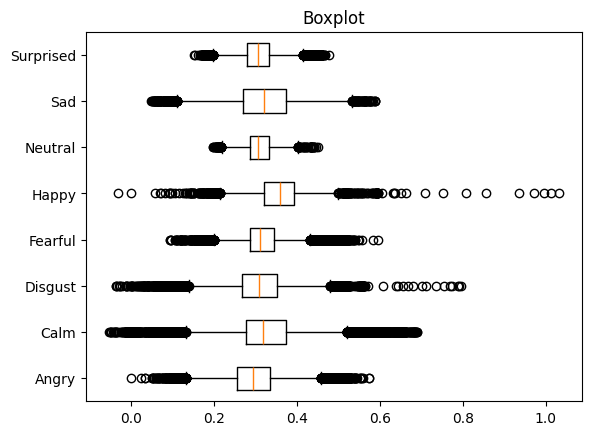

Angry -> IQR: 0.08135414761829951
Calm -> IQR: 0.09721108189827665
Disgust -> IQR: 0.08545456982306165
Fearful -> IQR: 0.05785720686845547
Happy -> IQR: 0.0713364419774683
Neutral -> IQR: 0.04613688270023797
Sad -> IQR: 0.10525619236189104
Surprised -> IQR: 0.054266242193123426
136 coordinates
IQR Tukey:
 Mean: emotion
Angry        3.002687
Calm         3.933789
Disgust      3.691104
Fearful      2.690651
Happy        1.895115
Neutral      0.684378
Sad          1.611813
Surprised    2.478892
dtype: float64
 Std: emotion
Angry        1.764197
Calm         3.236581
Disgust      3.175588
Fearful      1.944793
Happy        1.175044
Neutral      0.869442
Sad          1.458626
Surprised    1.938397
dtype: float64

Z-score (k=3):
 Mean: emotion
Angry        0.944421
Calm         0.471825
Disgust      0.826235
Fearful      0.790710
Happy        0.799111
Neutral      0.234498
Sad          0.492174
Surprised    0.718432
dtype: float64
 Std: emotion
Angry        0.514838
Calm         0.446507
Dis

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dados = pd.read_parquet("t1.1.gzip")
testIndex = pd.read_parquet("testIndex.gzip")
videoTable = pd.read_parquet("t1.2.gzip")
dados = dados[~dados["video"].isin(testIndex["video"])].copy()

d = np.sqrt((dados["x_45"] - dados["x_36"])**2 + (dados["y_45"] - dados["y_36"])**2)
dados["x54_d"] = (dados["x_54"] - dados["x_27"]) / d

#group by checking the video name in the videoTable, and getting the emotion from there
groups = dados.groupby(dados["video"].map(videoTable.set_index("video")["emotion"]))["x54_d"].apply(list)
#label the y-axis with the emotion names in the videoTable, in the order they appear in the groups
bp = plt.boxplot(groups,vert= False, labels=groups.index)
plt.title("Boxplot")

plt.show()

for i, box in enumerate(bp['boxes']):
    x_data = box.get_xdata()
    q1 = x_data[0]
    q3 = x_data[2]
    print(f"{groups.index[i]} -> IQR: {q3 - q1}")

cols = {}
for k in range(68):
    cols[f"x_{k}"] = (dados[f"x_{k}"] - dados["x_27"]) / d
    cols[f"y_{k}"] = (dados[f"y_{k}"] - dados["y_27"]) / d

norm = pd.DataFrame(cols)
coords = list(norm.columns)
print(len(coords), "coordinates")
#print(norm)
norm["emotion"] = dados["video"].map(videoTable.set_index("video")["emotion"])
norm["actor"] = dados["video"].map(videoTable.set_index("video")["actor"])
norm["video"] = dados["video"]

#IQR range with Tukey fences.
def rho_iqr(g):
    q1 = g.quantile(0.25)
    q3 = g.quantile(0.75)
    iqr = q3 - q1
    outlier = (g < q1 - 1.5 * iqr) | (g > q3 + 1.5 * iqr)   # True/False per value
    return 100 * outlier.mean()                              # % of frames flagged, per coordinate

#z score k=3 and k=4
def rho_z(g, k):
    z = (g - g.mean()) / g.std()
    outlier = z.abs() > k
    return 100 * outlier.mean()

by_emotion = norm.groupby("emotion")
#apply the functions to each group, for each coordinate
IQR_Tukey = by_emotion[coords].apply(rho_iqr)
Z_k3 = by_emotion[coords].apply(rho_z, k=3)
Z_k4 = by_emotion[coords].apply(rho_z, k=4)

#mean and standart deviantion of the density of outliers per emotion
print(f"IQR Tukey:\n Mean: {IQR_Tukey.mean(axis=1)}\n Std: {IQR_Tukey.std(axis=1)}\n")
print(f"Z-score (k=3):\n Mean: {Z_k3.mean(axis=1)}\n Std: {Z_k3.std(axis=1)}\n")
print(f"Z-score (k=4):\n Mean: {Z_k4.mean(axis=1)}\n Std: {Z_k4.std(axis=1)}\n")


Tukey's fences flag a greater density of outliers than the z-score, regardless of the emotion: IQR flags between 0.6% and 4.0% of frames, z-score with k=3 between 0.2% and 1.0%, and k=4 between 0.005% and 0.4%. The IQR rule is based on the quartiles, so it is stricter on frames that are only moderately far from the centre, while the z-score depends on the mean and standard deviation, which are themselves inflated by the extreme frames.

Neutral has the lowest density of outliers with all three rules. Calm, Disgust and Angry have the highest IQR densities. Calm drops the most when going to z-score, so its outliers are mostly moderate, whereas Happy keeps the highest density at k=4, which points to a few very extreme frames. For Calm and Disgust the standard deviation across coordinates is as large as the mean, so their outliers are concentrated in some coordinates; Angry has a similar mean but a lower standard deviation, so its outliers are spread more evenly. A flagged frame is an extreme value, not necessarily a tracking error, since strong expressions legitimately produce extremes.

Question 2.3 For one coordinate and one emotion, find which actors and which videos the flagged frames come 
from. Are they errors of the tracker or legitimate, extreme expressions? Should they be removed or 
corrected before the features are computed? Justify.

         count      mean  median   min   max
flagged                                     
False    17926  0.978932    0.98  0.88  0.98
True       816  0.978346    0.98  0.93  0.98
816 flagged of 18742 frames
                          flagged  frames  min_confidence actor
video                                                          
01-01-07-02-01-01-05.csv      124     130            0.93    05
01-01-07-02-01-02-05.csv      106     117            0.98    05
01-01-07-02-02-02-05.csv       95     136            0.98    05
01-01-07-02-01-01-03.csv       93     123            0.98    03
01-01-07-02-02-01-03.csv       62     115            0.98    03
01-01-07-02-02-01-20.csv       48     142            0.98    20
01-01-07-01-01-01-14.csv       47     112            0.98    14
01-01-07-01-01-02-03.csv       42     119            0.98    03
01-01-07-01-02-02-14.csv       35     112            0.98    14
01-01-07-02-01-02-06.csv       34     117            0.93    06
01-01-07-02-01-02-03.csv

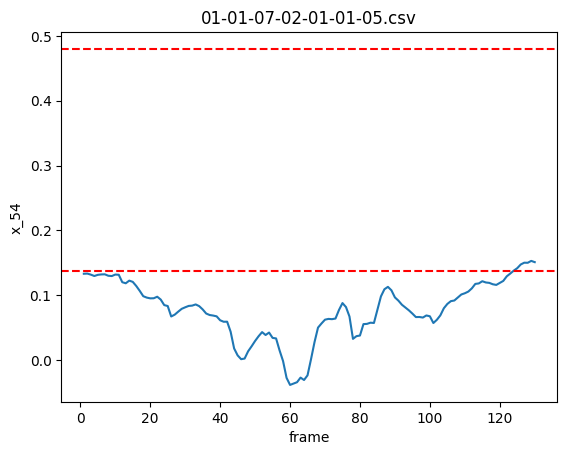

In [35]:
chosen_emotion = "Disgust"
chosen_coor = "x_54"
norm["confidence"] = dados["confidence"]
# Compare confidence in flagged and unflagged frames
print(
    sub.groupby("flagged")["confidence"]
       .agg(["count", "mean", "median", "min", "max"])
)
sub = norm[norm["emotion"] == chosen_emotion].copy()           # frames of the chosen emotion
q1, q3 = sub[chosen_coor].quantile([0.25, 0.75])
iqr = q3 - q1
sub["flagged"] = (sub[chosen_coor] < q1 - 1.5 * iqr) | (sub[chosen_coor] > q3 + 1.5 * iqr)
print(sub["flagged"].sum(), "flagged of", len(sub), "frames")

# flagged frames per video (only videos with at least one)
per_video = sub.groupby("video").agg(flagged=("flagged", "sum"), frames=("flagged", "size"), min_confidence=("confidence", "min"))
per_video = per_video[per_video["flagged"] > 0].sort_values("flagged", ascending=False)
per_video["actor"] = per_video.index.map(videoTable.set_index("video")["actor"])
print(per_video)

# flagged frames per actor
print(per_video.groupby("actor")["flagged"].agg(videos="count", frames="sum")
    .sort_values("frames", ascending=False))

v = per_video.index[0]
rows = (norm["video"] == v).to_numpy()
plt.plot(dados.loc[rows, "frame"].to_numpy(), norm.loc[rows, chosen_coor].to_numpy())
plt.axhline(q3 + 1.5 * iqr, color="r", ls="--")      # upper fence (add the lower one if needed)
plt.axhline(q1 - 1.5 * iqr, color="r", ls="--")      # lower fence
plt.xlabel("frame"); plt.ylabel(chosen_coor); plt.title(v); plt.show()


I do not belive that they are tracking errors. As we can see above, the min confidence of each video with an outlier frame is still high (0.88 to 0.98) so, it's more likely that they are legitimate extremes expressions and should be kept, as removing them misrepresents the population. 
The graph of the video with the most flagged frames shows the coordinate of the x_54 along the length of the video. It is almost completely bellow the IQR range. Could it be that this video was simply filmed with the actor lower then the other videos? Shouldn't normalization have taken care of that?